# Post-encoding analysis of thrombus images: latent space exploration

## 0. Imports

In [1]:
import os
import pandas as pd
import numpy as np
from tqdm.notebook import trange, tqdm
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import svm, metrics
from sklearn.linear_model import ElasticNet, Ridge, Lasso
import xgboost as xgb
import PIL
from PIL import Image
from matplotlib import gridspec
from statannotations.Annotator import Annotator
import matplotlib
import matplotlib.font_manager as font_manager
import io
import umap
from IPython.display import display

PIL.Image.MAX_IMAGE_PIXELS = 9999999999
%matplotlib inline

# whether to remove crops that are overlapping the outside of the image
REMOVE_OUTSIDE_CROPS = True
# aggregation function parameters: median, without encoding standardization
MERGE_METHOD_DICT = {"func": np.median, "name": "median", "standardize": False}

TASK = "task_K+ATP_vs_TE"  # compare all atypical, including cancer and other atypical, versus typical etiologies

# Declare paths (images, encodings, coordinate arrays)
training_labels_path = r"C:\Users\flori\OneDrive - univ-angers.fr\Documents\Home\Research\Bureau\data-final-2025june30\training-data\training_data_annotations.xlsx"
training_predictions_dir = r"C:\Users\flori\OneDrive - univ-angers.fr\Documents\Home\Research\Bureau\data-final-2025june30\training-data\features-aQ_last"
validation_predictions_dir = r"C:\Users\flori\OneDrive - univ-angers.fr\Documents\Home\Research\Bureau\data-final-2025june30\validation-data\features-aQ_last"
training_images_root_path = r"C:\Users\flori\OneDrive - univ-angers.fr\Documents\Home\Research\Bureau\data-final-2025june30\training-data\raw"
validation_images_root_path = r"C:\Users\flori\OneDrive - univ-angers.fr\Documents\Home\Research\Bureau\data-final-2025june30\validation-data\raw"


## 1. Load and aggregate data

Aggregate encoded features by patient.

In [2]:
# Function that will allow loading and aggregating data
def load_and_aggregate_feature_encodings(predictions_directory):
    # look for slides in the specified directory
    found_slidenames = [f[:-11] for f in os.listdir(predictions_directory) if f[-10:] == "coords.npy"]
    samples_array = []
    data_array = []

    # parse patient directories and look for image data (possible multiple images per patient)
    found_slidenames_aggregated = {}
    for slidename in found_slidenames:
        patientid = slidename[:8].upper()
        if patientid not in found_slidenames_aggregated.keys():
            found_slidenames_aggregated[patientid] = []
        found_slidenames_aggregated[patientid].append(slidename)

    for patientid, slidenames in tqdm(found_slidenames_aggregated.items(), desc="Aggregating encodings"):
        predictions_array = []
        coords_array = []
        # for each slide
        for slidename in slidenames:
            # load predictions (numpy array) = encodings
            predictions_array.append(np.load(os.path.join(predictions_directory, slidename + "_features.npy")))
            # load crop coordinates (relative to the whole slide image) so we can reconstruct the whole slide heatmap
            coords_array.append(np.load(os.path.join(predictions_directory, slidename + "_coords.npy")))
        predictions_array = np.concatenate(predictions_array, axis=0)
        coords_array = np.concatenate(coords_array, axis=0)

        # should we remove crops overlapping the borders of the image?
        if REMOVE_OUTSIDE_CROPS:
            keepf_1 = np.logical_and(coords_array[:, 2] < 1, coords_array[:, 3] < 1)
            keepf_0 = np.logical_and(coords_array[:, 0] > 0, coords_array[:, 1] > 0)
            keepf = np.logical_and(keepf_0, keepf_1)
            predictions_array = predictions_array[keepf, :]
            
        samples_array.append("/".join(slidenames))
        data_array.append(MERGE_METHOD_DICT["func"](predictions_array, axis=0))

    return samples_array, data_array

try:
    # Load Training
    training_samples_array, training_data_array = load_and_aggregate_feature_encodings(training_predictions_dir)
    training_dataset = pd.concat([pd.Series(training_samples_array, name="SlideID"), pd.DataFrame(np.stack(training_data_array), columns=[f"feat_{i + 1}" for i in range(training_data_array[0].shape[0])])], axis=1)
    training_dataset.insert(loc=1, column="PatientID", value=training_dataset.SlideID.apply(lambda x: x[:8].upper()))

    # Metadata
    training_metadata = pd.read_excel(training_labels_path)
    training_metadata.columns = ('PatientID', 'Etiology_Full', 'Etiology_Short', 'Etiology_Binary', 'Thrombus_Color')
    training_metadata.PatientID = training_metadata.PatientID.str.upper()

    training_metadata.Etiology_Short = training_metadata.Etiology_Short.map({'OTHER': 'Other', 'ATYPICAL': 'Atypical', 'CANCER': 'Cancer'})
    training_metadata.Etiology_Binary = training_metadata.Etiology_Binary.map({'OTHER': 'Other', 'CANCER/ATYPICAL': 'Cancer/atypical'})
    training_metadata.Thrombus_Color = training_metadata.Thrombus_Color.map({'RED': 'Red', 'WHITE': 'White'})

    if TASK == "task_K+ATP_vs_TE":
        training_metadata["Etiology_binary"] = training_metadata.Etiology_Binary.map({'Other': 0, 'Cancer/atypical': 1})
    elif TASK == "task_K_vs_TE+ATP":
        training_metadata["Etiology_binary"] = training_metadata.Etiology_Short.map({'Other': 0, 'Atypical': 0, 'Cancer': 1})
    elif TASK == "task_K_vs_ATP":
        training_metadata["Etiology_binary"] = training_metadata.Etiology_Short.map({'Other': np.nan, 'Atypical': 0, 'Cancer': 1})

    training_metadata["Color_binary"] = training_metadata.Thrombus_Color.map({'Red': 0, 'White': 1})

    training_dataset_enriched = training_metadata.merge(training_dataset, on="PatientID")

    # remove samples with unknown etiology
    training_dataset_enriched = training_dataset_enriched[training_dataset_enriched.Etiology_Full != 'INCONNU']

    # Load Validation
    validation_samples_array, validation_data_array = load_and_aggregate_feature_encodings(validation_predictions_dir)
    validation_dataset = pd.concat([pd.Series(validation_samples_array, name="SlideID"), pd.DataFrame(np.stack(validation_data_array), columns=[f"feat_{i + 1}" for i in range(validation_data_array[0].shape[0])])], axis=1)
    validation_dataset.insert(loc=1, column="PatientID", value=validation_dataset.SlideID.apply(lambda x: x[:8].upper()))
    
    print(f"Finished loading: {len(training_dataset_enriched)} training samples, {len(validation_dataset)} validation samples.")
    display(training_dataset_enriched.head())
except Exception as e:
    print(f"Unable to load data (check paths?): {e}")


Aggregating encodings:   0%|          | 0/202 [00:00<?, ?it/s]

Aggregating encodings:   0%|          | 0/38 [00:00<?, ?it/s]

Finished loading: 157 training samples, 38 validation samples.


,PatientID,Etiology_Full,Etiology_Short,Etiology_Binary,Thrombus_Color,Etiology_binary,Color_binary,SlideID,feat_1,feat_2,...,feat_503,feat_504,feat_505,feat_506,feat_507,feat_508,feat_509,feat_510,feat_511,feat_512
0,21H07903,CARDIOEMBOLIQUE,Other,Other,NaN,0,NaN,21H07903_HPS_001/21H07903_HPS_002/21H07903_HPS...,0.000000,0.000000,...,0.008753,1.524029,1.520268,0.000000,0.018815,0.264953,0.000000,0.000000,0.010411,0.000000
1,22H01859,DISSECTION,Other,Other,NaN,0,NaN,22H01859_HPS,0.000000,0.000000,...,0.100180,1.984432,0.020665,1.677052,0.472705,0.159431,0.715689,0.000000,0.231687,0.000000
3,20H09152,ATHEROTHROMBOTIQUE,Other,Other,Red,0,0.0,20H09152_HPS_001/20H09152_HPS_002/20H09152_HPS...,0.199531,0.000307,...,0.866716,0.460190,0.664904,0.051037,0.012989,0.148840,0.755398,0.090976,0.101772,0.101704
4,20H09343,ATHEROTHROMBOTIQUE,Other,Other,Red,0,0.0,20H09343_HPS,0.731197,0.000000,...,0.468348,1.039490,1.216384,0.000000,0.558836,1.925241,0.486276,0.192636,0.410041,0.250089
5,20H10071,ATHEROTHROMBOTIQUE,Other,Other,Red,0,0.0,20H10071_HPS_001/20H10071_HPS_002/20H10071_HPS...,0.149152,0.384096,...,0.058282,0.384182,0.459194,0.036626,0.042008,1.712955,0.273551,1.291505,0.000000,0.179702


## 2. Unsupervised UMAP visualization (2D / 3D)

Compute UMAP on final aggregated encodings and display 2D and 3D plots, according to annotated thrombus color or origin.

C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\umap\umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


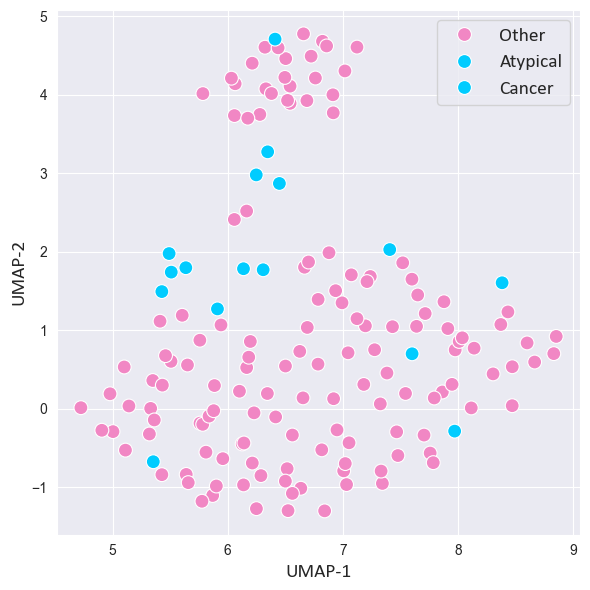

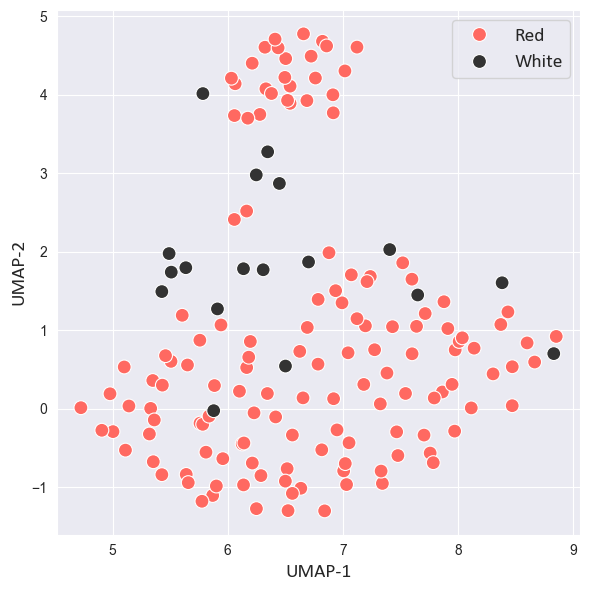

C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\flori\anaconda3\envs\py311_torch21gpu_feb25\Lib\site-packages\umap\umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


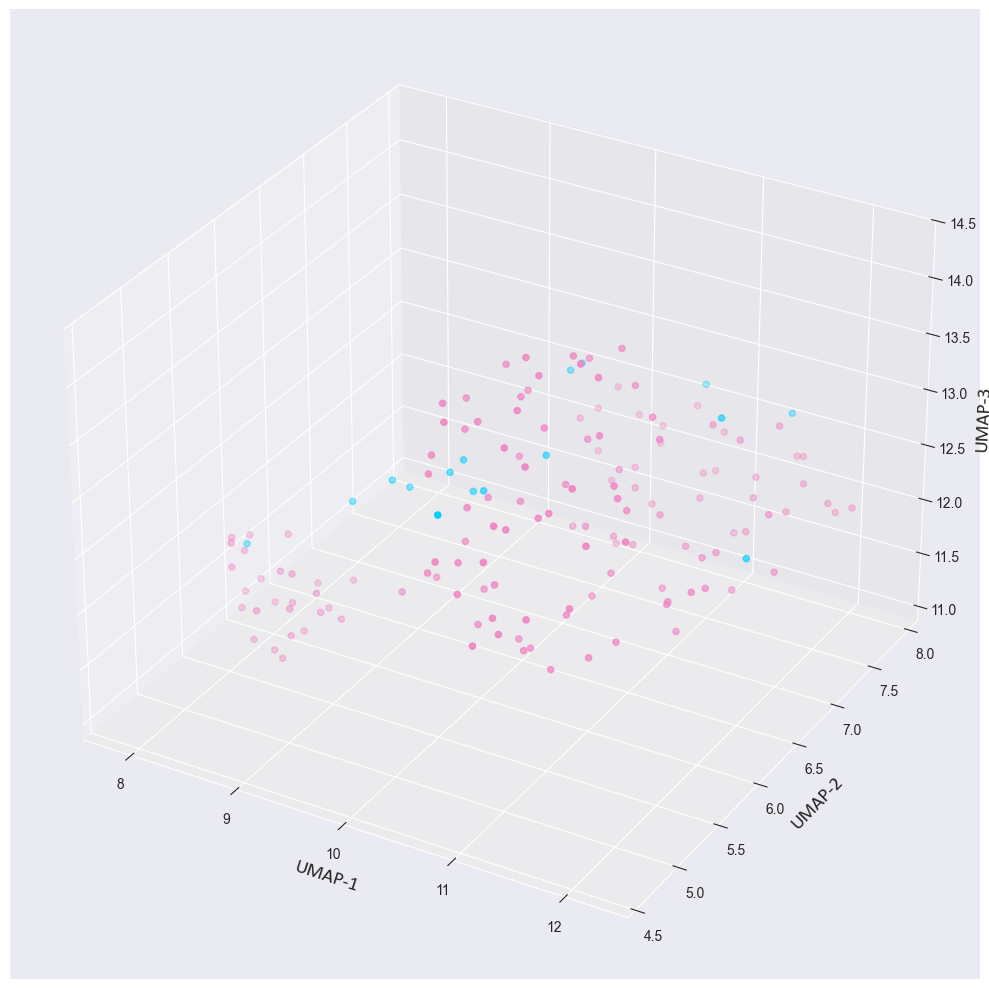

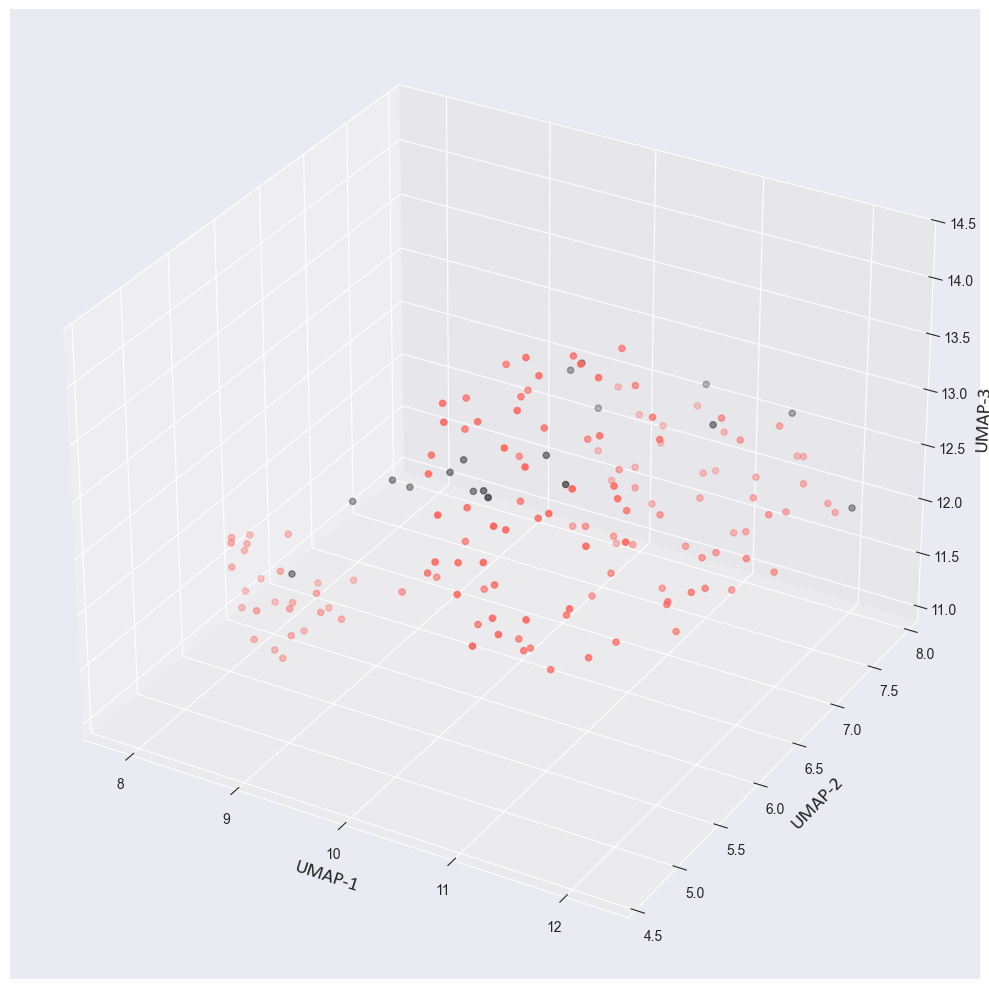

In [3]:
if 'training_dataset_enriched' in locals() and TASK == "task_K+ATP_vs_TE":
    for N_DIM in (2, 3):
        UMAP_N_NEIGHBORS = 500
        features_originalspace = training_dataset_enriched[[f"feat_{i + 1}" for i in range(512)]].values
        features_lowspace = umap.UMAP(n_neighbors=UMAP_N_NEIGHBORS, random_state=44, n_components=N_DIM).fit_transform(features_originalspace)
        features_lowspace_names = [f'UMAP-{i+1}' for i in range(N_DIM)]

        plot_data_source = pd.DataFrame(features_lowspace, columns=features_lowspace_names)
        plot_data_source["Etiology_Short"] = training_dataset_enriched.Etiology_Short.values
        plot_data_source["Thrombus_Color"] = training_dataset_enriched.Thrombus_Color.values

        legend_font_params = font_manager.FontProperties(family='Calibri', weight='normal', style='normal', size=14)
        labels_font_params = {"fontname": "Calibri", "fontweight": "normal", "fontsize": 14}
        palette_dict = {"Other": "#f187c4", "Cancer": "#00ccff", "Atypical": "#00ccff", "Red": "#ff6961", "White": "#333333"}

        for hue in ["Etiology_Short", "Thrombus_Color"]:
            plot_data = plot_data_source[~plot_data_source[hue].isna()].copy()
            if N_DIM == 2:
                plt.figure(figsize=(6, 6))
                ax = sns.scatterplot(x="UMAP-1", y="UMAP-2", data=plot_data, hue=hue, palette=palette_dict, s=100)
                ax.legend(prop=legend_font_params)
                plt.xlabel("UMAP-1", **labels_font_params)
                plt.ylabel("UMAP-2", **labels_font_params)
                plt.tight_layout()
                plt.show()
            elif N_DIM == 3:
                fig = plt.figure(figsize=(10, 10))
                ax = fig.add_subplot(111, projection='3d')
                ax.scatter(plot_data['UMAP-1'], plot_data['UMAP-2'], plot_data['UMAP-3'], c=[palette_dict[e] for e in plot_data[hue]], marker='o')
                ax.set_xlabel(features_lowspace_names[0], **labels_font_params)
                ax.set_ylabel(features_lowspace_names[1], **labels_font_params)
                ax.set_zlabel(features_lowspace_names[2], **labels_font_params)
                plt.tight_layout()
                plt.show()


## 3. Classification (bootstrapping machine learning)

Evaluate ML classification model performance for predicting thrombus color or origin based on aggregated encodings.

In [4]:
if 'training_dataset_enriched' in locals():
    ML_MODELS = ("svm_0.5_rbf", "ridge_0.5")  # which architecture should be trained
    N_BOOTSTRAPS = 1000  # number of bootstrapping iterations

    full_training_X = training_dataset_enriched[[f"feat_{i + 1}" for i in range(512)]].values
    full_training_y_color = training_dataset_enriched.Color_binary.values
    full_training_y_etiology = training_dataset_enriched.Etiology_binary.values

    if TASK == 'task_K_vs_ATP':
        full_training_X = full_training_X[~np.isnan(full_training_y_etiology)]
        full_training_y_color = full_training_y_color[~np.isnan(full_training_y_etiology)]
        full_training_y_etiology = full_training_y_etiology[~np.isnan(full_training_y_etiology)]

    training_X_color = full_training_X[~np.isnan(full_training_y_color)]
    training_y_color = full_training_y_color[~np.isnan(full_training_y_color)]

    training_X_etiology = full_training_X[~np.isnan(full_training_y_etiology)]
    training_y_etiology = full_training_y_etiology[~np.isnan(full_training_y_etiology)]

    test_X = validation_dataset[[f"feat_{i + 1}" for i in range(512)]].values

    def run_preds(ml_model, X_data):
        try:
            tmp_probs = ml_model.predict_proba(X_data)[:, 1]
        except:
            tmp_probs = ml_model.predict(X_data)
        tmp_cls = (tmp_probs >= .5) * 1
        return tmp_probs, tmp_cls

    ml_training_results = []
    for ml_model_name in ML_MODELS:
        if ml_model_name == "svm_0.5_rbf":
            ml_model = svm.SVC(C=0.5, kernel="rbf", probability=True)
        elif ml_model_name == "ridge_0.5":
            ml_model = Ridge(alpha=0.5)

        ml_results_metrics = {"color": {"f1": [], "roc-auc": [], "sensitivity": [], "specificity": []},
                              "etiology": {"f1": [], "roc-auc": [], "sensitivity": [], "specificity": []}}
        ml_results_extpreds = {"color": [], "etiology": []}
        
        for random_state in trange(N_BOOTSTRAPS, desc=f'Bootstrapping {ml_model_name=}'):
            for variable, training_X, training_y in zip(["color", "etiology"], [training_X_color, training_X_etiology], [training_y_color, training_y_etiology]):
                train_indices = np.random.RandomState(seed=44 + random_state).choice(np.arange(len(training_X)), size=len(training_X), replace=True)
                test_indices = np.setdiff1d(np.arange(len(training_X)), train_indices)
                
                if len(np.unique(training_y[train_indices])) != 2 or len(np.unique(training_y[test_indices])) != 2:
                    continue
                    
                ml_model.fit(training_X[train_indices], training_y[train_indices])
                internal_preds_proba, internal_preds_class = run_preds(ml_model, training_X[test_indices])
                
                ml_results_metrics[variable]["f1"].append(metrics.f1_score(training_y[test_indices], internal_preds_class))
                ml_results_metrics[variable]["roc-auc"].append(float(metrics.roc_auc_score(training_y[test_indices], internal_preds_proba)))
                tn, fp, fn, tp = metrics.confusion_matrix(training_y[test_indices], internal_preds_class).ravel()
                ml_results_metrics[variable]["sensitivity"].append(float(tp / (tp + fn)))
                ml_results_metrics[variable]["specificity"].append(float(tn / (tn + fp)))
                
                external_preds_proba, external_preds_class = run_preds(ml_model, test_X)
                ml_results_extpreds[variable].append(external_preds_class)

        for variable in ["color", "etiology"]:
            ml_model_performance_dict = {"ml_model_name": ml_model_name, "variable": variable}
            for score in ml_results_metrics[variable].keys():
                score_mean, score_low, score_high = float(np.mean(ml_results_metrics[variable][score])), *[float(v) for v in np.quantile(ml_results_metrics[variable][score], q=[.025, .975])]
                ml_model_performance_dict.update({f"{score}_mean": score_mean, f"{score}_95%cilow": score_low, f"{score}_95%cihigh": score_high})
            ml_training_results.append(ml_model_performance_dict)
            
            extpreds_stacked = np.stack(ml_results_extpreds[variable], axis=1)
            validation_dataset[f"{variable}==1_{ml_model_name}_pred_mean"] = np.mean(extpreds_stacked, axis=1)
            validation_dataset[f"{variable}==1_{ml_model_name}_pred_95%cilow"], validation_dataset[f"{variable}==1_{ml_model_name}_pred_95%cihigh"] = np.quantile(extpreds_stacked, [.025, .975], axis=1)

    print("ML results performance:")
    display(pd.DataFrame(ml_training_results))


Bootstrapping ml_model_name='svm_0.5_rbf':   0%|          | 0/1000 [00:00<?, ?it/s]

Bootstrapping ml_model_name='ridge_0.5':   0%|          | 0/1000 [00:00<?, ?it/s]

ML results performance:


,ml_model_name,variable,f1_mean,f1_95%cilow,f1_95%cihigh,roc-auc_mean,roc-auc_95%cilow,roc-auc_95%cihigh,sensitivity_mean,sensitivity_95%cilow,sensitivity_95%cihigh,specificity_mean,specificity_95%cilow,specificity_95%cihigh
0,svm_0.5_rbf,color,0.625547,0.285714,0.875000,0.927762,0.788438,0.996303,0.571584,0.200000,1.0,0.975245,0.912242,1.0
1,svm_0.5_rbf,etiology,0.633612,0.200000,0.909091,0.896555,0.708137,1.000000,0.561865,0.111111,1.0,0.984703,0.925926,1.0
2,ridge_0.5,color,0.641571,0.285714,0.909441,0.912475,0.711551,1.000000,0.552013,0.200000,1.0,0.985698,0.940000,1.0
3,ridge_0.5,etiology,0.517879,0.000000,0.800000,0.823170,0.557585,0.990402,0.490989,0.000000,1.0,0.965489,0.903846,1.0


## 4. Compute fold-changes

Extract the most highly discriminant features for either color or origin..

In [5]:
if 'training_dataset_enriched' in locals():
    N_TOP_FEATURES = 3
    X_data, Y_data_etiology, Y_data_color = [], [], []

    for patient_id, slide_filenames, patient_label_etiology, patient_label_color in zip(training_dataset_enriched.PatientID, training_dataset_enriched.SlideID, training_dataset_enriched.Etiology_binary, training_dataset_enriched.Color_binary):
        for slide_filename in slide_filenames.split("/"):
            predictions_array = np.load(os.path.join(training_predictions_dir, slide_filename + "_features.npy"))
            coords_array = np.load(os.path.join(training_predictions_dir, slide_filename + "_coords.npy"))
            if REMOVE_OUTSIDE_CROPS:
                keepf = np.logical_and(np.logical_and(coords_array[:, 0] > 0, coords_array[:, 1] > 0),
                                       np.logical_and(coords_array[:, 2] < 1, coords_array[:, 3] < 1))
                predictions_array = predictions_array[keepf, :]
            X_data.append(predictions_array)
            Y_data_etiology.extend([patient_label_etiology, ] * len(predictions_array))
            Y_data_color.extend([patient_label_color, ] * len(predictions_array))

    X_data = np.concatenate(X_data)
    Y_data_etiology = np.array(Y_data_etiology)
    Y_data_color = np.array(Y_data_color)

    foldchanges_etiology = X_data[Y_data_etiology == 1, :].mean(axis=0) / X_data[Y_data_etiology == 0, :].mean(axis=0)
    log2foldchanges_etiology = np.log2(foldchanges_etiology)

    foldchanges_color = X_data[Y_data_color == 1, :].mean(axis=0) / X_data[Y_data_color == 0, :].mean(axis=0)
    log2foldchanges_color = np.log2(foldchanges_color)

    LOWEST_LOG2FC_ETIOLOGY = np.argsort(log2foldchanges_etiology)[:N_TOP_FEATURES][::-1]
    HIGHEST_LOG2FC_ETIOLOGY = np.argsort(-log2foldchanges_etiology)[:N_TOP_FEATURES]

    LOWEST_LOG2FC_COLOR = np.argsort(log2foldchanges_color)[:N_TOP_FEATURES][::-1]
    HIGHEST_LOG2FC_COLOR = np.argsort(-log2foldchanges_color)[:N_TOP_FEATURES]
    
    print("Calculated most discriminant features:")
    print("    Features with highest log2(fold-change) for color: " + ", ".join([f"{feat}" for feat in HIGHEST_LOG2FC_COLOR]))
    print("    Features with lowest log2(fold-change) for color: " + ", ".join([f"{feat}" for feat in LOWEST_LOG2FC_COLOR]))
    print("    Features with highest log2(fold-change) for origin: " + ", ".join([f"{feat}" for feat in HIGHEST_LOG2FC_ETIOLOGY]))
    print("    Features with lowest log2(fold-change) for origin: " + ", ".join([f"{feat}" for feat in LOWEST_LOG2FC_ETIOLOGY]))


Calculated most discriminant features:
    Features with highest log2(fold-change) for color: 135, 467, 268
    Features with lowest log2(fold-change) for color: 159, 399, 288
    Features with highest log2(fold-change) for origin: 139, 225, 135
    Features with lowest log2(fold-change) for origin: 349, 178, 399


## 5. Visualisation Boxplots (Résultats Inline)
Affichage direct des diagrammes à moustaches avec Annotator (tests statistiques).


Génération des boxplots globaux...
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:2.419e-02 U_stat=1.250e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:5.166e-01 U_stat=2.210e+02
Red_Other vs. White_Other: Mann-Whitney-Wilcoxon test two-sided, P_val:1.997e-01 U_stat=5.070e+02
Red_Cancer/atypical vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:4.237e-01 U_stat=1.700e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:1.505e-01 U_stat=2.000e+01
Red_Other vs. Red_Cancer/atypical: Mann

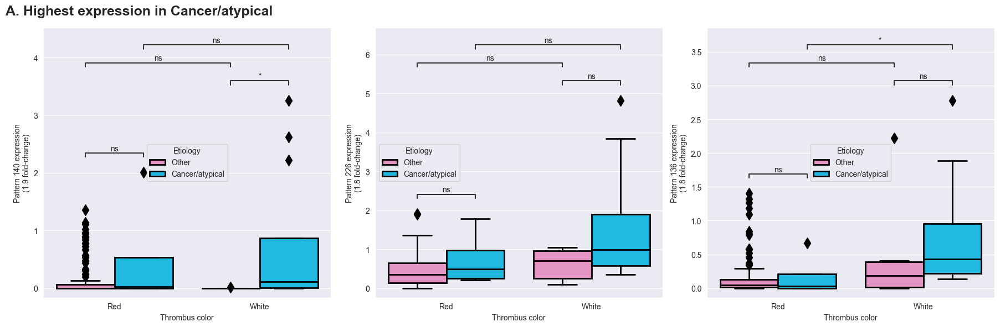

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:1.423e-02 U_stat=6.100e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:6.029e-01 U_stat=3.070e+02
Red_Other vs. White_Other: Mann-Whitney-Wilcoxon test two-sided, P_val:7.587e-01 U_stat=3.690e+02
Red_Cancer/atypical vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:9.484e-02 U_stat=3.700e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:3.652e-01 U_stat=4.500e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P

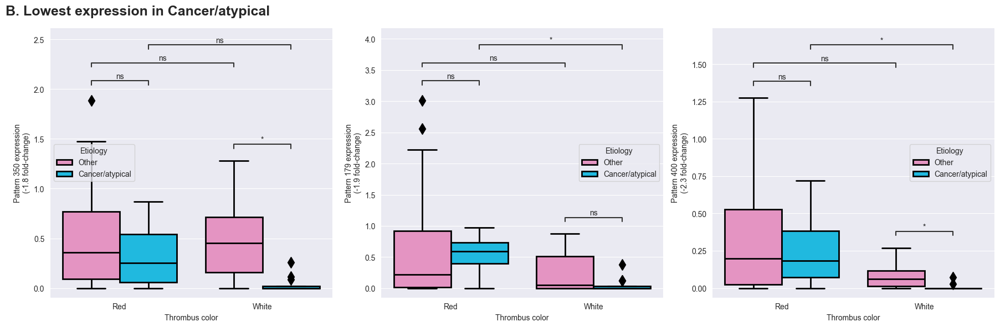

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:1.464e-01 U_stat=2.000e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:5.865e-01 U_stat=3.090e+02
Red_Other vs. White_Other: Mann-Whitney-Wilcoxon test two-sided, P_val:5.860e-01 U_stat=3.460e+02
Red_Cancer/atypical vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:4.176e-02 U_stat=7.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:9.626e-01 U_stat=3.700e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P

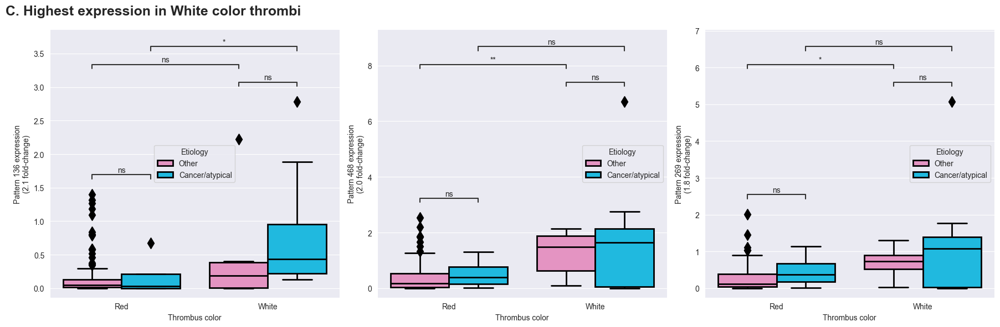

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:3.395e-03 U_stat=6.400e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:6.223e-01 U_stat=2.270e+02
Red_Other vs. White_Other: Mann-Whitney-Wilcoxon test two-sided, P_val:7.786e-02 U_stat=5.695e+02
Red_Cancer/atypical vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:1.058e-03 U_stat=4.800e+01
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

White_Other vs. White_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P_val:2.960e-02 U_stat=5.600e+01
Red_Other vs. Red_Cancer/atypical: Mann-Whitney-Wilcoxon test two-sided, P

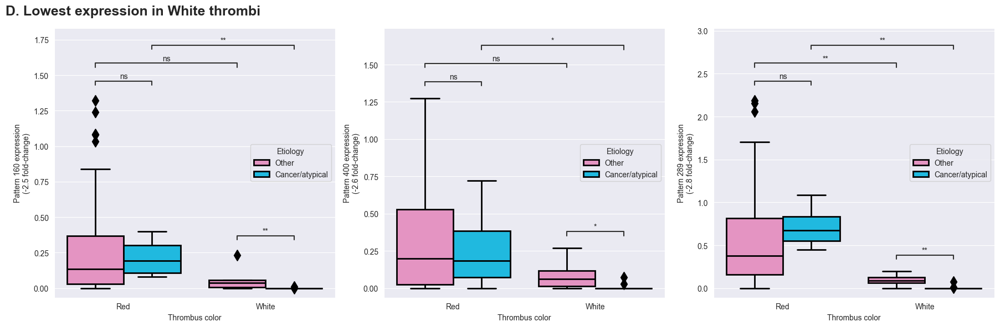

In [6]:
if 'training_dataset_enriched' in locals():
    if TASK == "task_K+ATP_vs_TE":
        etiology_pos_label = "Cancer/atypical"
        etiology_neg_label = "Other"
        etiology_column = training_dataset_enriched.Etiology_Binary.values
        CUSTOM_COLORS = {"Other": "#f187c4", "Cancer/atypical": "#00ccff"}
    elif TASK == "task_K_vs_TE+ATP":
        etiology_pos_label = "Cancer"
        etiology_neg_label = "Non-cancer atypical/TE"
        etiology_column = training_dataset_enriched.Etiology_Short.map({'Other': 'Non-cancer atypical/TE', 'Cancer': 'Cancer', 'Atypical': 'Non-cancer atypical/TE'}).values
        CUSTOM_COLORS = {"Cancer": "#00ccff", "Non-cancer atypical/TE": "#f187c4"}
    elif TASK == "task_K_vs_ATP":
        etiology_pos_label = "Cancer"
        etiology_neg_label = "Non-cancer atypical"
        etiology_column = training_dataset_enriched.Etiology_Short.map({'Other': np.nan, 'Cancer': 'Cancer', 'Atypical': 'Non-cancer atypical'}).values
        CUSTOM_COLORS = {"Cancer": "#00ccff", "Non-cancer atypical": "#f187c4"}

    boxplot_graphics = {'flierprops': {"marker": "d", "markerfacecolor": "black", "markersize": 10}, 'linewidth': 2, 'linecolor': 'black'}
    legend_font_params = font_manager.FontProperties(family='Calibri', size=14)

    def make_box_plot(chosen_features, feature_logfcs, figname, annotate=False):
        plt.figure(figsize=(18, 6))
        for f_i, (f, f_logfc) in enumerate(zip(chosen_features, feature_logfcs)):
            f_name = f"feat_{f + 1}"
            boxplot_data = pd.DataFrame({"pattern_expr": training_dataset_enriched[f_name], "thrombus_color": training_dataset_enriched.Thrombus_Color.values, "Etiology": etiology_column})
            boxplot_kwargs = {"data": boxplot_data, "x": "thrombus_color", "y": "pattern_expr", "hue": "Etiology", "order": ['Red', 'White'], "palette": list(CUSTOM_COLORS.values())}
            
            ax = plt.subplot(1, 3, f_i + 1)
            sns.boxplot(**{**boxplot_kwargs, **boxplot_graphics})
            
            if annotate:
                box_pairs = [(("Red", etiology_neg_label), ("Red", etiology_pos_label)),
                             (("White", etiology_neg_label), ("White", etiology_pos_label)),
                             (("Red", etiology_neg_label), ("White", etiology_neg_label)),
                             (("Red", etiology_pos_label), ("White", etiology_pos_label))]
                annotator = Annotator(ax, box_pairs, **boxplot_kwargs)
                annotator.configure(test='Mann-Whitney', text_format='star', loc='inside').apply_and_annotate()
                
            plt.ylabel(f'Pattern {f + 1} expression\n({f_logfc:.1f} fold-change)')
            plt.xlabel('Thrombus color')
        plt.suptitle(figname, x=0, horizontalalignment='left', verticalalignment='top', fontsize=18, fontweight='bold')
        plt.tight_layout()
        plt.show()

    # Affichage de l'ensemble d'entraînement global
    print("Génération des boxplots globaux...")
    for chosen_features, feature_logfcs, figname in [
            [HIGHEST_LOG2FC_ETIOLOGY, log2foldchanges_etiology[HIGHEST_LOG2FC_ETIOLOGY], f"A. Highest expression in {etiology_pos_label}"],
            [LOWEST_LOG2FC_ETIOLOGY, log2foldchanges_etiology[LOWEST_LOG2FC_ETIOLOGY], f"B. Lowest expression in {etiology_pos_label}"],
            [HIGHEST_LOG2FC_COLOR, log2foldchanges_color[HIGHEST_LOG2FC_COLOR], "C. Highest expression in White color thrombi"],
            [LOWEST_LOG2FC_COLOR, log2foldchanges_color[LOWEST_LOG2FC_COLOR], "D. Lowest expression in White thrombi"]]:
        make_box_plot(chosen_features, feature_logfcs, figname, annotate=True)


## 6. Analyze top crops

For each identified feature with highest/lowest fold change, we will search for the image patch with highest encoding expression for this feature.

Scanning patches:   0%|          | 0/2076 [00:00<?, ?it/s]

  0%|          | 0/12 [00:00<?, ?it/s]

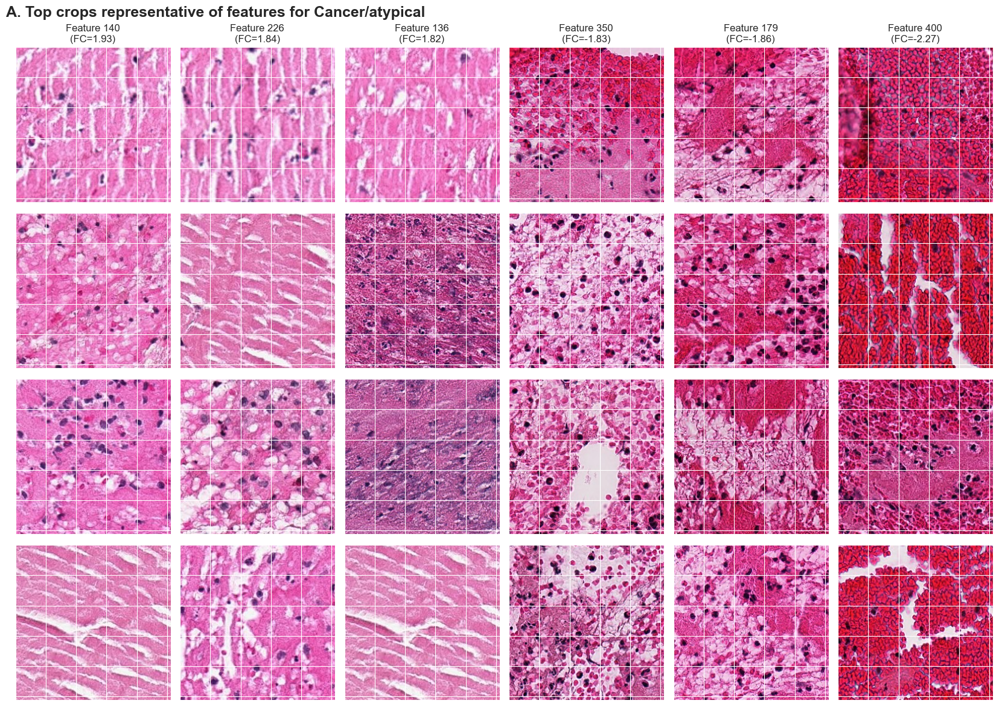

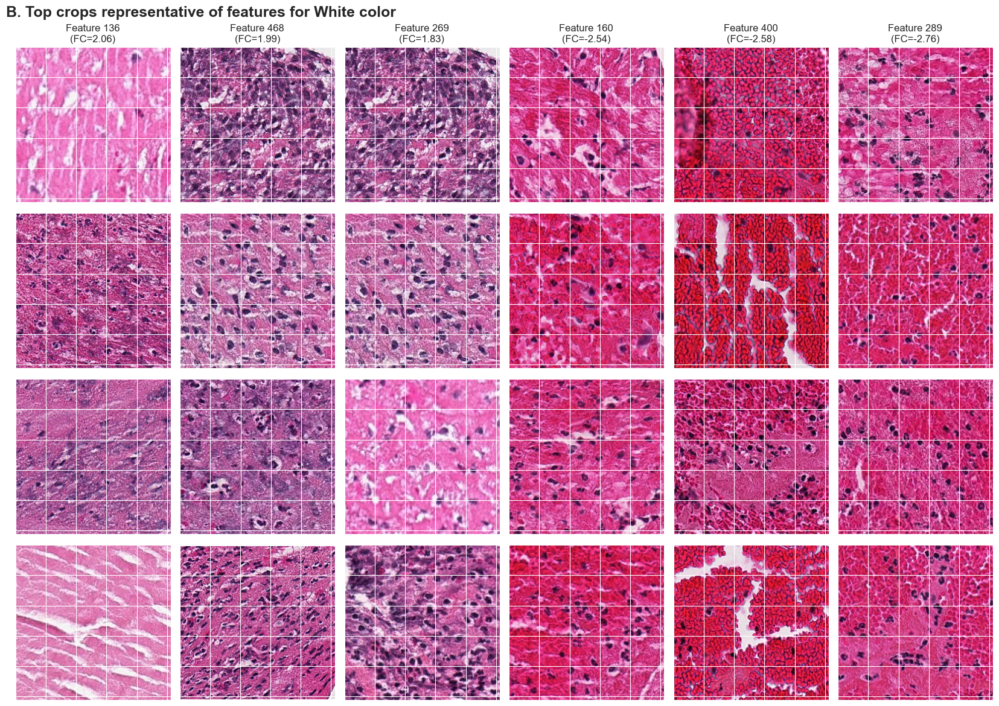

In [7]:
if 'training_dataset_enriched' in locals():
    # chosen features = features with highest & lowest fold change
    chosen_features = [*HIGHEST_LOG2FC_ETIOLOGY, *LOWEST_LOG2FC_ETIOLOGY, *HIGHEST_LOG2FC_COLOR, *LOWEST_LOG2FC_COLOR]
    # find logfc of those features
    chosen_features_logfc = [*log2foldchanges_etiology[HIGHEST_LOG2FC_ETIOLOGY], *log2foldchanges_etiology[LOWEST_LOG2FC_ETIOLOGY], *log2foldchanges_color[HIGHEST_LOG2FC_COLOR], *log2foldchanges_color[LOWEST_LOG2FC_COLOR]]

    feature_scan = []
    # parse patches
    for feat_file in tqdm(os.listdir(training_predictions_dir), desc="Scanning patches"):
        if feat_file[-13:] == "_features.npy":
            tmp_arr = np.load(os.path.join(training_predictions_dir, feat_file))
            highest_expression_per_feature_value = tmp_arr[:, chosen_features].max(axis=0)
            highest_expression_per_feature_position = tmp_arr[:, chosen_features].argmax(axis=0)
            slide_feature_dict = {"patient_id": feat_file[:8].upper(), "slide_id": feat_file[:-13], 
                                  **{f"{int(feat_num)}_value": float(feat_value) for feat_num, feat_value in zip(chosen_features, highest_expression_per_feature_value)}, 
                                  **{f"{int(feat_num)}_position": int(feat_value) for feat_num, feat_value in zip(chosen_features, highest_expression_per_feature_position)}}
            feature_scan.append(slide_feature_dict)

    feature_scan = pd.DataFrame(feature_scan)
    scan_results = []
    # for each feature => get 'expression'
    for feat_num in chosen_features:
        feature_scan_sort = feature_scan.sort_values(by=f"{feat_num}_value", ascending=False)
        feature_scan_sort = feature_scan_sort[~feature_scan_sort.patient_id.duplicated()].iloc[:4, :]
        scan_results.append([feature_scan_sort.slide_id.values.tolist(), feature_scan_sort[f"{feat_num}_position"].values.tolist()])

    top_crop_images = []
    # go back to the coordinates to find the patch image data
    for feat_i, (feat_num, top_crops) in enumerate(tqdm(zip(chosen_features, scan_results), total=len(chosen_features))):
        top_crops_temp = []
        for slide_id, crop_position in zip(*top_crops):
            slide_predcoords = np.load(os.path.join(training_predictions_dir, slide_id + "_coords.npy"))
            im = Image.open(os.path.join(training_images_root_path, slide_id, slide_id + ".jpg"))
            xstart, ystart, xend, yend = slide_predcoords[crop_position, :]
            xstart, ystart, xend, yend = int(xstart * im.size[0]), int(ystart * im.size[1]), int(xend * im.size[0]), int(yend * im.size[1])
            top_crops_temp.append(im.crop((xstart, ystart, xend, yend)))
        top_crop_images.append(top_crops_temp)

    # plot images with a heatmap
    plt.figure(figsize=(16.5, 12))
    gs = gridspec.GridSpec(len(top_crop_images[0]), 6)
    for feat_i, (feat_num, logfc, top_crops) in enumerate(zip(chosen_features[:6], chosen_features_logfc[:6], top_crop_images[:6])):
        for crop_i, crop_im in enumerate(top_crops):
            plt.subplot(gs[crop_i, feat_i])
            plt.imshow(crop_im)
            plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
            if crop_i == 0: plt.title(f"Feature {feat_num + 1}\n(FC={logfc:.2f})")
    plt.suptitle(f"A. Top crops representative of features for {etiology_pos_label}", fontsize=18, fontweight='bold', x=0, horizontalalignment='left')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(16.5, 12))
    gs = gridspec.GridSpec(len(top_crop_images[0]), 6)
    for feat_i, (feat_num, logfc, top_crops) in enumerate(zip(chosen_features[6:], chosen_features_logfc[6:], top_crop_images[6:])):
        for crop_i, crop_im in enumerate(top_crops):
            plt.subplot(gs[crop_i, feat_i])
            plt.imshow(crop_im)
            plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
            if crop_i == 0: plt.title(f"Feature {feat_num + 1}\n(FC={logfc:.2f})")
    plt.suptitle("B. Top crops representative of features for White color", fontsize=18, fontweight='bold', x=0, horizontalalignment='left')
    plt.tight_layout()
    plt.show()
